# Supplementary Figure 2

Panels a,b show how often authentic and composition-scrambled peptide queries of one healthy-stool acquisition match a protein of the 233.5-million-sequence reservoir, by query length. Panels c,d show how accepted peptides and selected proteins change with the minimum lookup length and the top-scoring fraction (58 acquisitions, 19 arms). Panels e,f (the continuation) show the exploratory bag and mass-substitution lookup comparison (48 acquisitions) and a separate six-acquisition fragment audit.

Run from the repository root: `python paper.py build SFig02`. Panels a-d and e,f are each one canvas in the original producers, so each is regenerated and checked as one canvas.

In [1]:
from pathlib import Path
import sys
UNIT = Path.cwd()                 # the notebook runs with its own directory as cwd
REPO = UNIT.parents[1]
sys.path[:0] = [str(REPO), str(UNIT)]
SD = REPO / "source_data" / UNIT.name
OUT = REPO / "build" / UNIT.name   # rendered panels; gitignored
OUT.mkdir(parents=True, exist_ok=True)
from style import fl_style as fl
import panels
fl.init()
from IPython.display import Image, display

## Panels a-d

a, fraction of distinct queries that match at least one reservoir protein, by length (9-50 residues), for the authentic predictions and five composition-preserving scrambles (seeds 20260901, 20260913-20260916); the inset enlarges the scrambles at 9-13 residues. b, number of distinct authentic queries per length (the denominator). c,d, median accepted peptides (with exclusive quartiles) and median selected proteins over 58 acquisitions for minimum lookup lengths 6-12 at top 30% (c) and top-scoring fractions 5-100% at minimum length nine (d).

Claims: "The fraction of scrambled queries matching a reservoir protein fell from 8.1–8.9% for nine-residue queries to 0.7–1.1% at ten residues, with no match in 86,000 query–seed evaluations at ≥13 residues" (v28d line 59); "Selection sensitivity used the same 58 healthy-stool acquisitions for 19 settings" (v28d line 679).

n and unit: a,b one acquisition, distinct query (sequence) within arm and seed; c,d 58 acquisitions per arm, the same acquisitions in every arm. Test: none (descriptive fractions, medians and exclusive quartiles).

{'title_bbox': (108.6468734741211, 6.780389785766602, 402.5669860839844, 19.59539031982422), 'numeric_labels_unchanged': True}


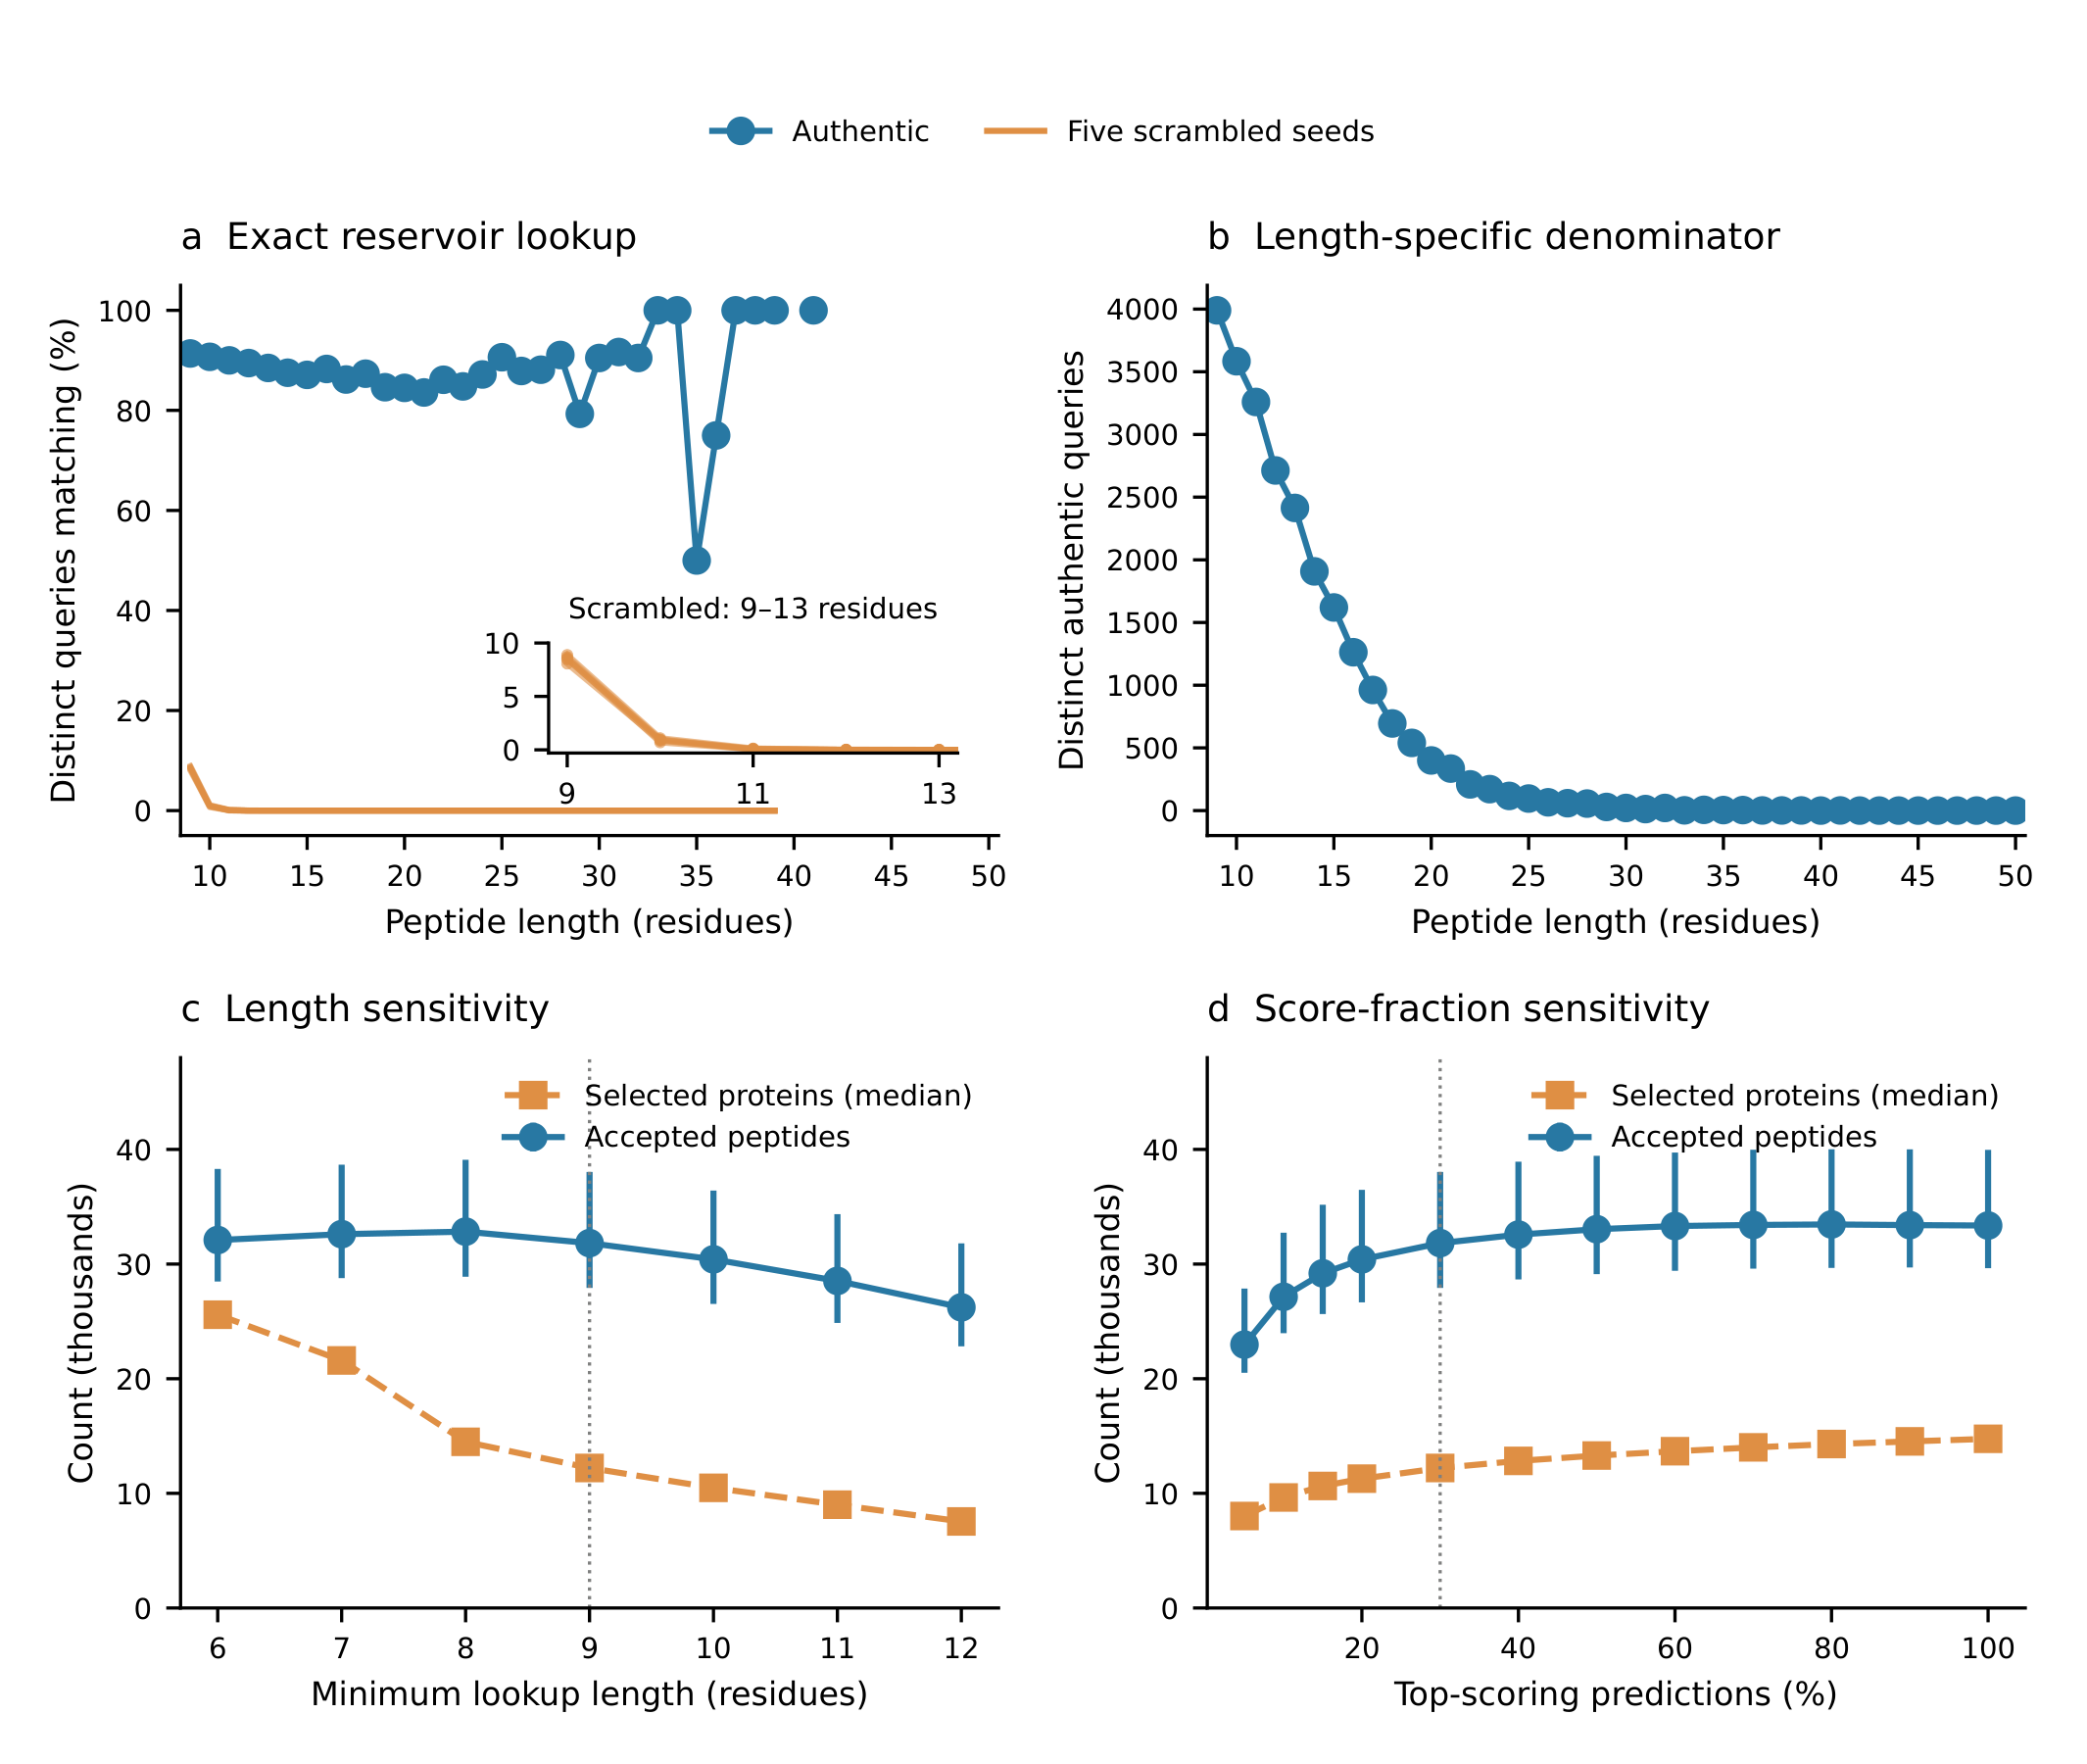

n_scrambled_seeds 5
n_scrambled_seeds_word five
authentic_len9_denominator 3990
scrambled_len9_denominators 5571;5572;5572;5572;5572
scrambled_len10_denominators 5136;5136;5136;5136;5135
scrambled_len9_min_pct 8.076094759511845
scrambled_len9_max_pct 8.883704235463028
scrambled_len10_min_pct 0.7009345794392523
scrambled_len10_max_pct 1.0903426791277258
scrambled_ge13_query_seed_evaluations 85835
scrambled_ge13_matches 0
authentic_len9_pct 91.37844611528823
authentic_distinct_queries_total 24560
observations 1102
arms 19
acquisitions 58
distinct_settings 18
max_relative_difference_vs_summary 8.153200337090993e-17
production_peptides_median 31829.0
production_peptides_q1 27918.25
production_peptides_q3 38034.0
production_selected_proteins_median 12212.5
production_selected_proteins_q1 11025.75
production_selected_proteins_q3 13419.75


In [2]:
panels.panel_abcd(SD, OUT / "panel_abcd.pdf")
print(panels.compose_abcd(OUT / "panel_abcd.pdf", OUT / "SFig02_v28f.pdf", OUT / "SFig02_v28f.png"))
import fitz
fitz.open(OUT / "panel_abcd.pdf")[0].get_pixmap(dpi=300, alpha=False).save(OUT / "panel_abcd.png")
display(Image(filename=str(OUT / "SFig02_v28f.png"), width=700))
for k, v in panels.stat_ab_lookup(SD).items():
    print(k, v)
for k, v in panels.stat_cd_grid(SD).items():
    print(k, v)

## Panels e,f

e, gained (blue) and lost (vermilion) peptide-acquisition identifications of each relaxed-lookup arm relative to exact lookup, summed over 48 acquisitions (15 CAMPI, 32 healthy stool, 1 CapScan) after within-acquisition deduplication at nominal peptide q≤0.01; the right column is the net. f, of 215 gained composition-preserving rearrangement pairs in six acquisitions, 193 had no diagnostic annotated fragment ion and 22 had at least one.

Claims: "admitting recorded bags gained 6,961 and lost 5,941 peptide–acquisition identifications relative to exact lookup (net +1,020)" and "In six acquisitions, 193 of 215 gained identifications ... had no annotated fragment ion distinguishing the two orders" (v28d line 67).

n and unit: e 48 acquisitions per arm, counts of peptide-acquisition identifications; f 215 same-spectrum comparison pairs in six acquisitions. Test: none (descriptive counts; the legend states no inferential error bars).

(2440, 1844)


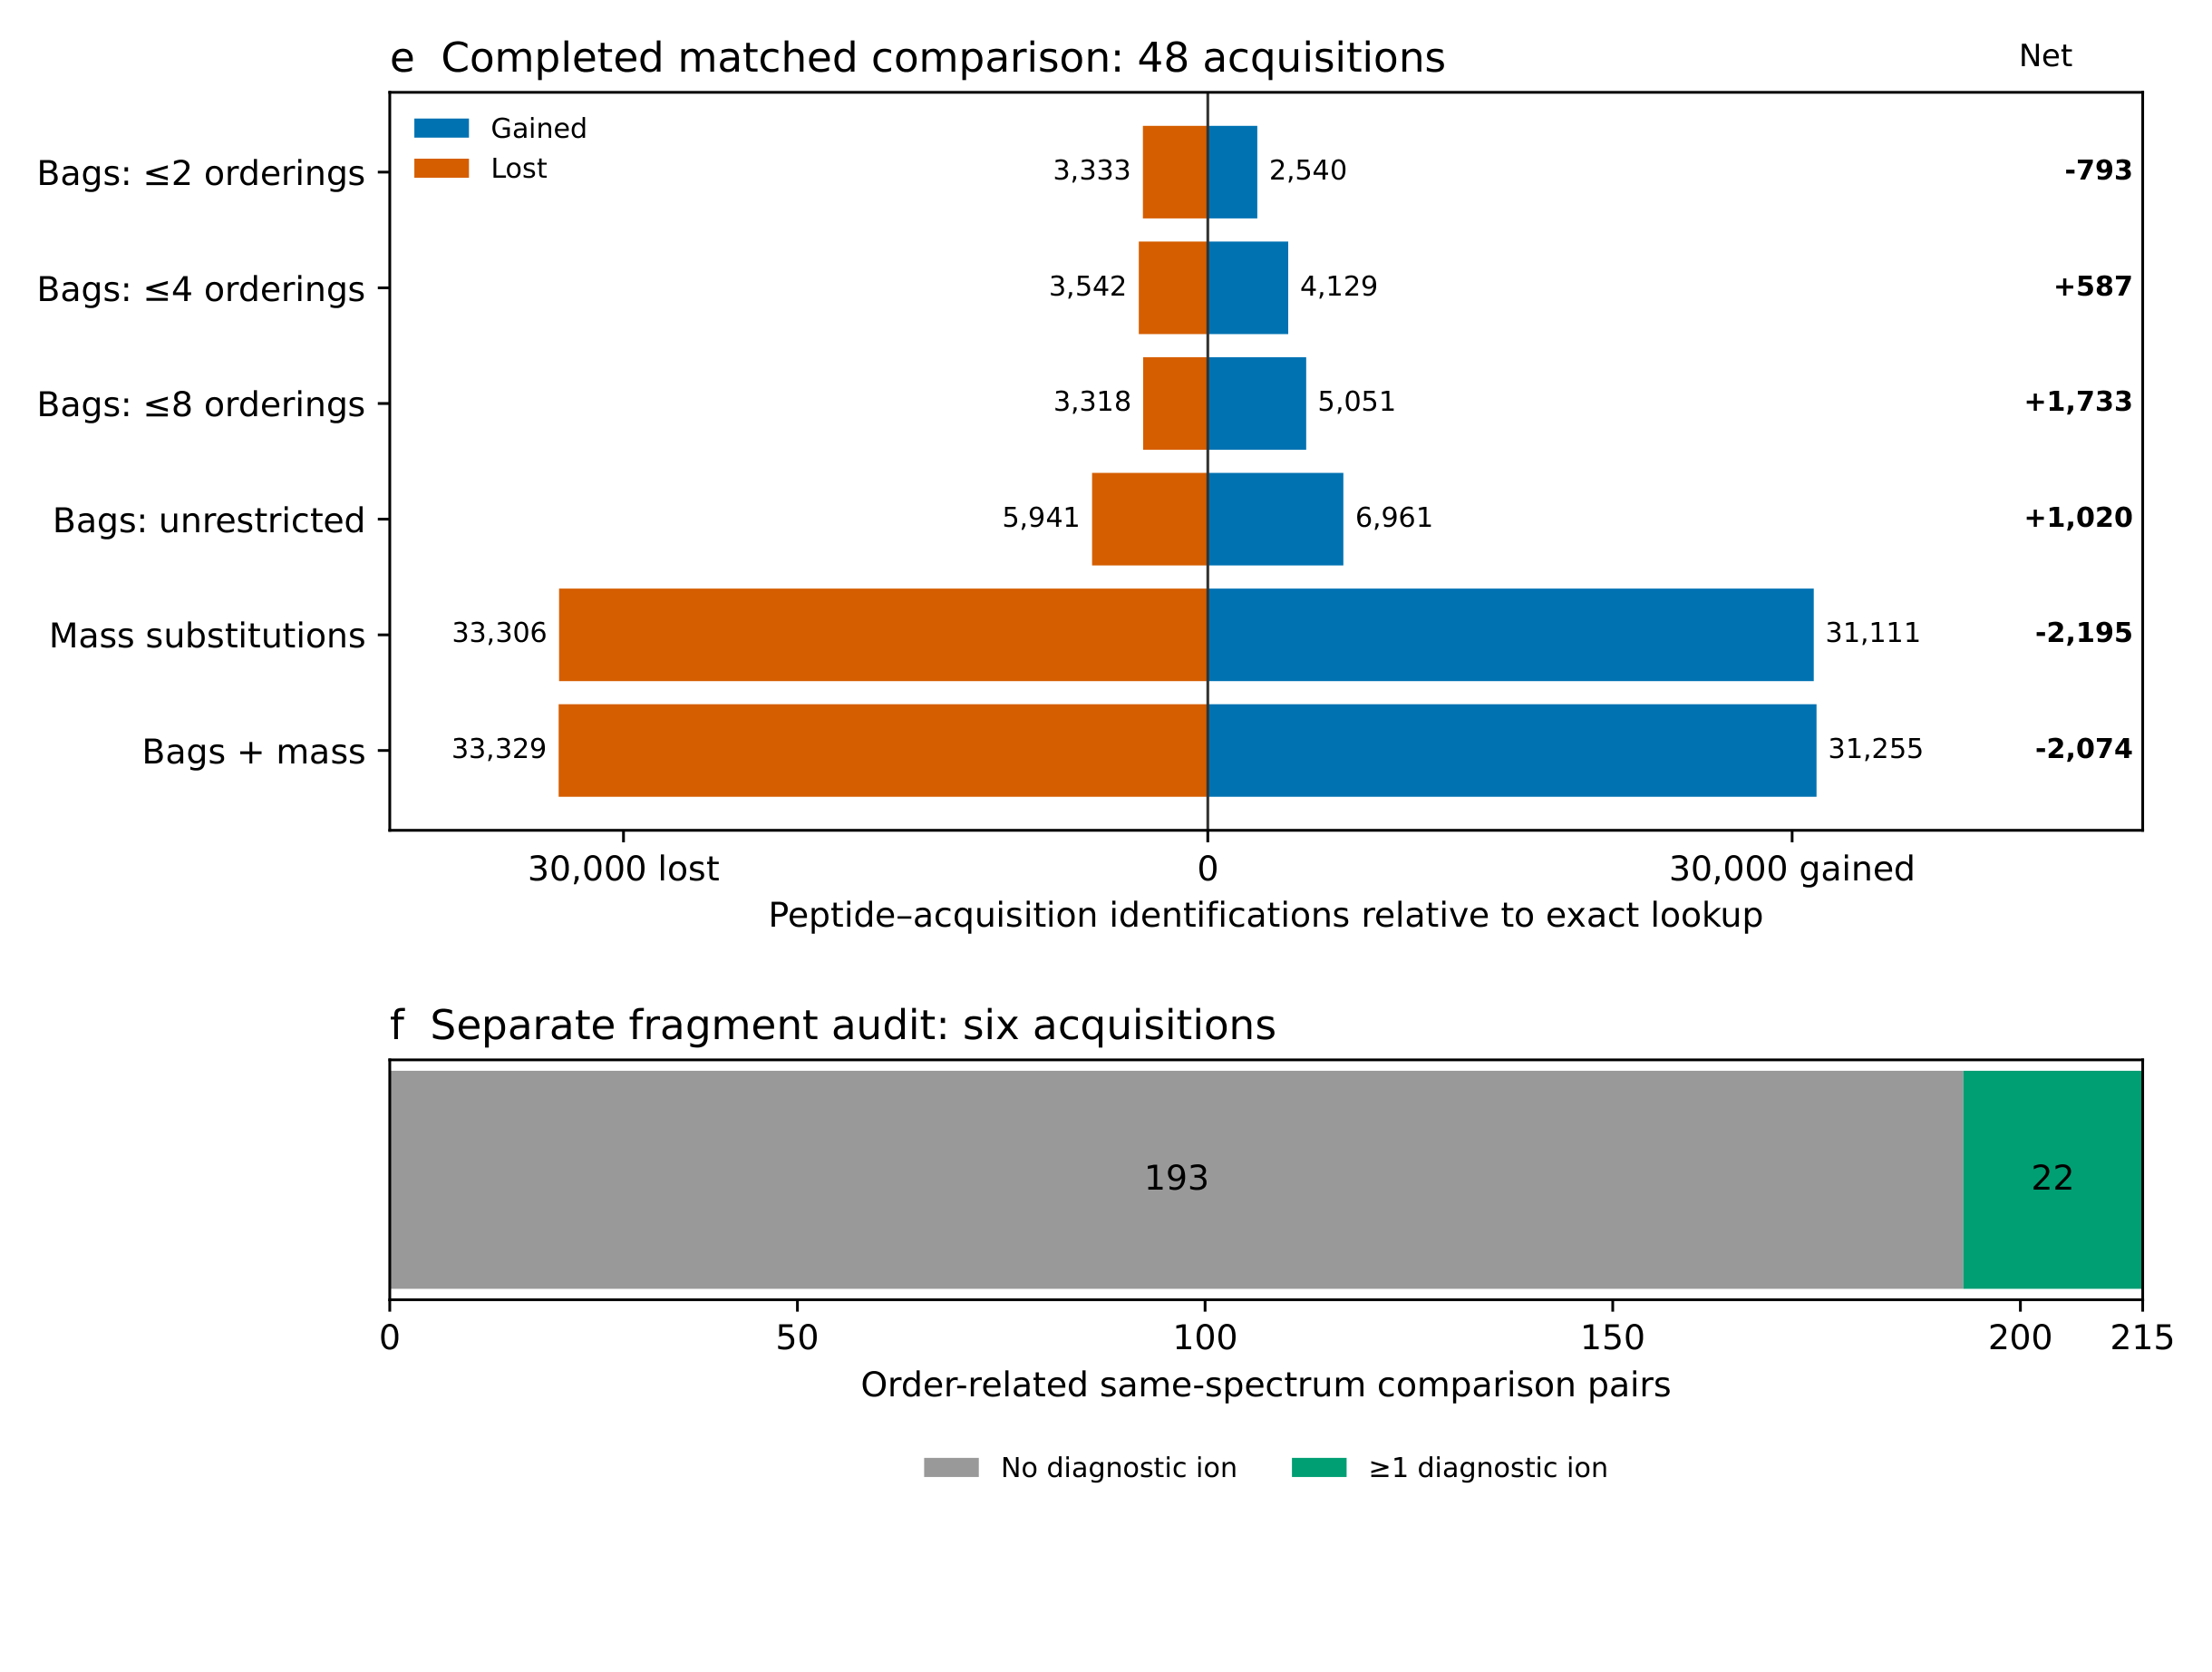

acquisitions 48
arm_rows 336
arms 7
arms_word seven
cohort_HSTOOL 32
cohort_CAMPI 15
cohort_CAPSCAN 1
cohort_CAPSCAN_word one
bags_all_gained 6961
bags_all_lost 5941
bags_all_net 1020
bags_all_positive_acquisitions 38
bags_le2_gained 2540
bags_le2_lost 3333
bags_le2_net -793
bags_le2_positive_acquisitions 27
bags_le4_gained 4129
bags_le4_lost 3542
bags_le4_net 587
bags_le4_positive_acquisitions 34
bags_le8_gained 5051
bags_le8_lost 3318
bags_le8_net 1733
bags_le8_positive_acquisitions 37
comb_all_gained 31255
comb_all_lost 33329
comb_all_net -2074
comb_all_positive_acquisitions 13
exact_gained 0
exact_lost 0
exact_net 0
exact_positive_acquisitions 0
mass_all_gained 31111
mass_all_lost 33306
mass_all_net -2195
mass_all_positive_acquisitions 13
hstool_acquisitions 32
hstool_mass_net -5242
hstool_mass_positive 3
mass_all_net_loss 2195
le8_eligible_rows 908037
eligible_rows 976861
le8_eligible_pct 92.95457593250217
fragment_acquisitions 6
fragment_acquisitions_word six
fragment_pairs 215
f

In [3]:
panels.panel_ef(SD, OUT / "panel_ef.pdf")
print(panels.compose_ef(OUT / "panel_ef.pdf", OUT / "SFig02_continued_v28f.png"))
fitz.open(OUT / "panel_ef.pdf")[0].get_pixmap(dpi=300, alpha=False).save(OUT / "panel_ef.png")
display(Image(filename=str(OUT / "SFig02_continued_v28f.png"), width=700))
for k, v in {**panels.stat_e_bags(SD), **{'fragment_' + k: v for k, v in panels.stat_f_fragment(SD).items()}}.items():
    print(k, v)

## v30 house style (panels a-f)

The v30 figure redraws both canvases from the same tables in the house style: Söhne type, ink, Okabe-Ito colours by meaning (authentic and accepted peptides blue, scrambled and selected proteins orange, gained blue, lost vermilion), drawn at the placed widths (160 mm for a-d, 155 mm for e,f). Subpanel titles are removed (their content is in the legend), the net values of e become right-hand tick labels, and the ≤/≥ labels are composed from Söhne glyphs. `build_v30` first runs the producers above with saving intercepted and asserts that every plotted value, axis limit and scale is identical.


<repo>/figures/SFig02/panels.py:802: UserWarning: SFig02_v30.pdf is 160.00 mm wide, not 88 or 180 mm (nearest 180). compose.py will refuse it. If it is a near miss, the cause is almost always a bbox that cropped the canvas -- REDRAW at the placed width; do not scale and do not pad.
  pdf, _ = fl.save(fg, out_dir / stem, formats=('pdf',))


v30 values identical to producer: a-d True | e,f True
label strings lost (titles and composed labels only): ['Evidence selection and exact-lookup specificity', 'Scrambled: 9–13 residues', 'a  Exact reservoir lookup', 'b  Length-specific denominator', 'c  Length sensitivity', 'd  Score-fraction sensitivity'] ['Bags: ≤2 orderings', 'Bags: ≤4 orderings', 'Bags: ≤8 orderings', 'e  Completed matched comparison: 48 acquisitions', 'f  Separate fragment audit: six acquisitions', '≥1 diagnostic ion']
png px: {'SFig02_v30': (1890, 1597), 'SFig02_continued_v30': (1831, 1384)}


<repo>/figures/SFig02/panels.py:802: UserWarning: SFig02_continued_v30.pdf is 155.00 mm wide, not 88 or 180 mm (nearest 180). compose.py will refuse it. If it is a near miss, the cause is almost always a bbox that cropped the canvas -- REDRAW at the placed width; do not scale and do not pad.
  pdf, _ = fl.save(fg, out_dir / stem, formats=('pdf',))


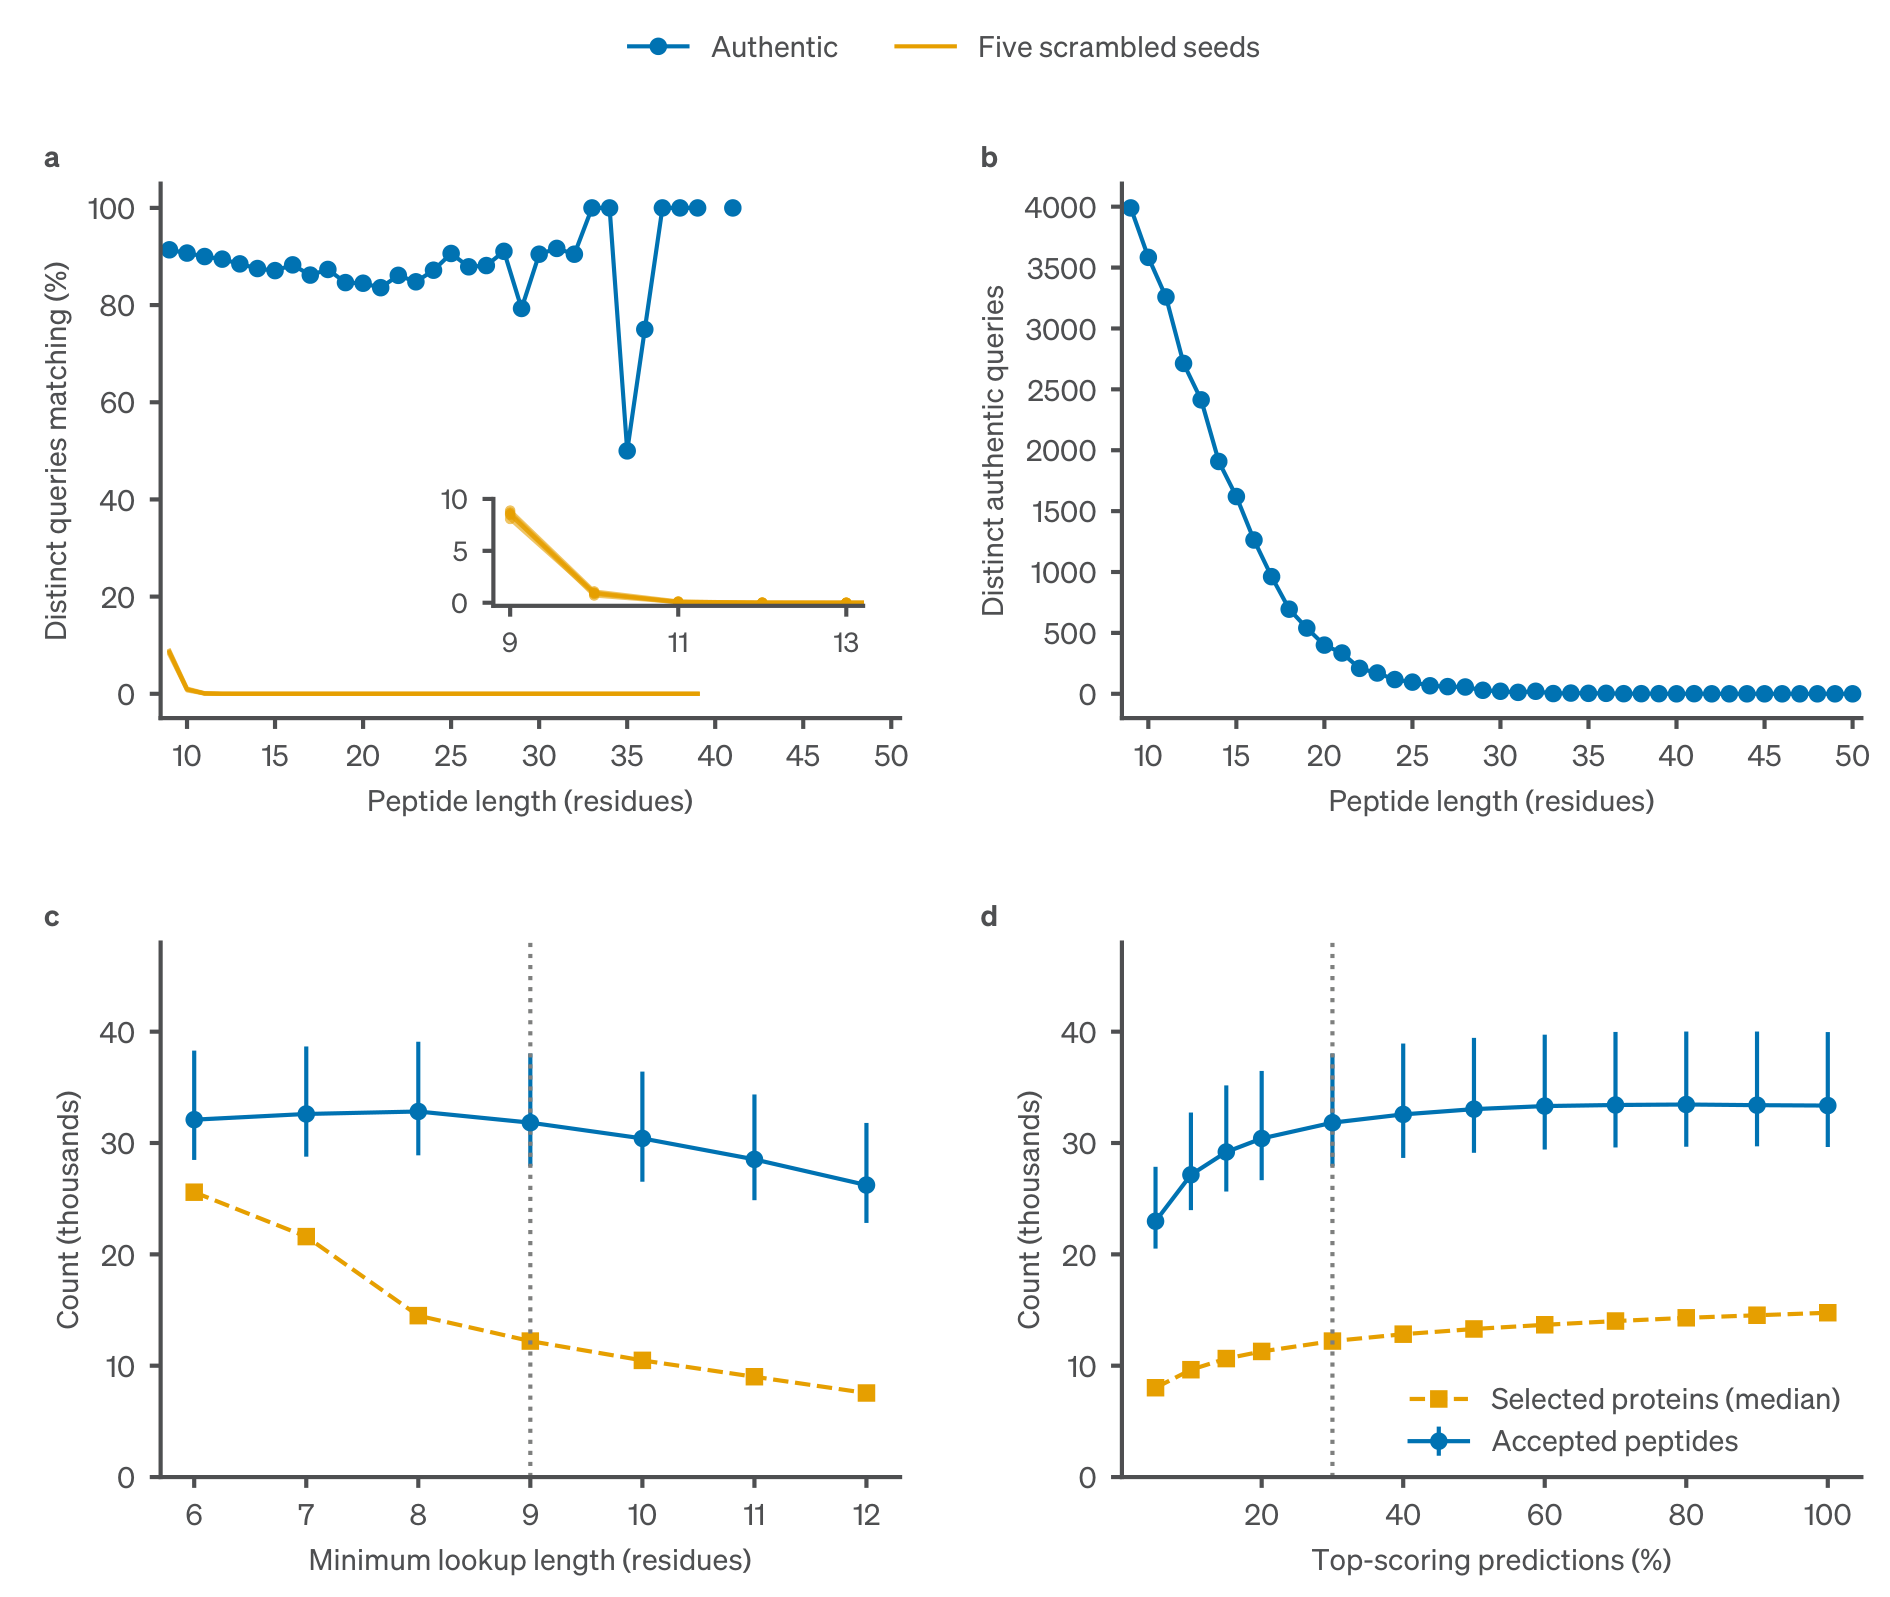

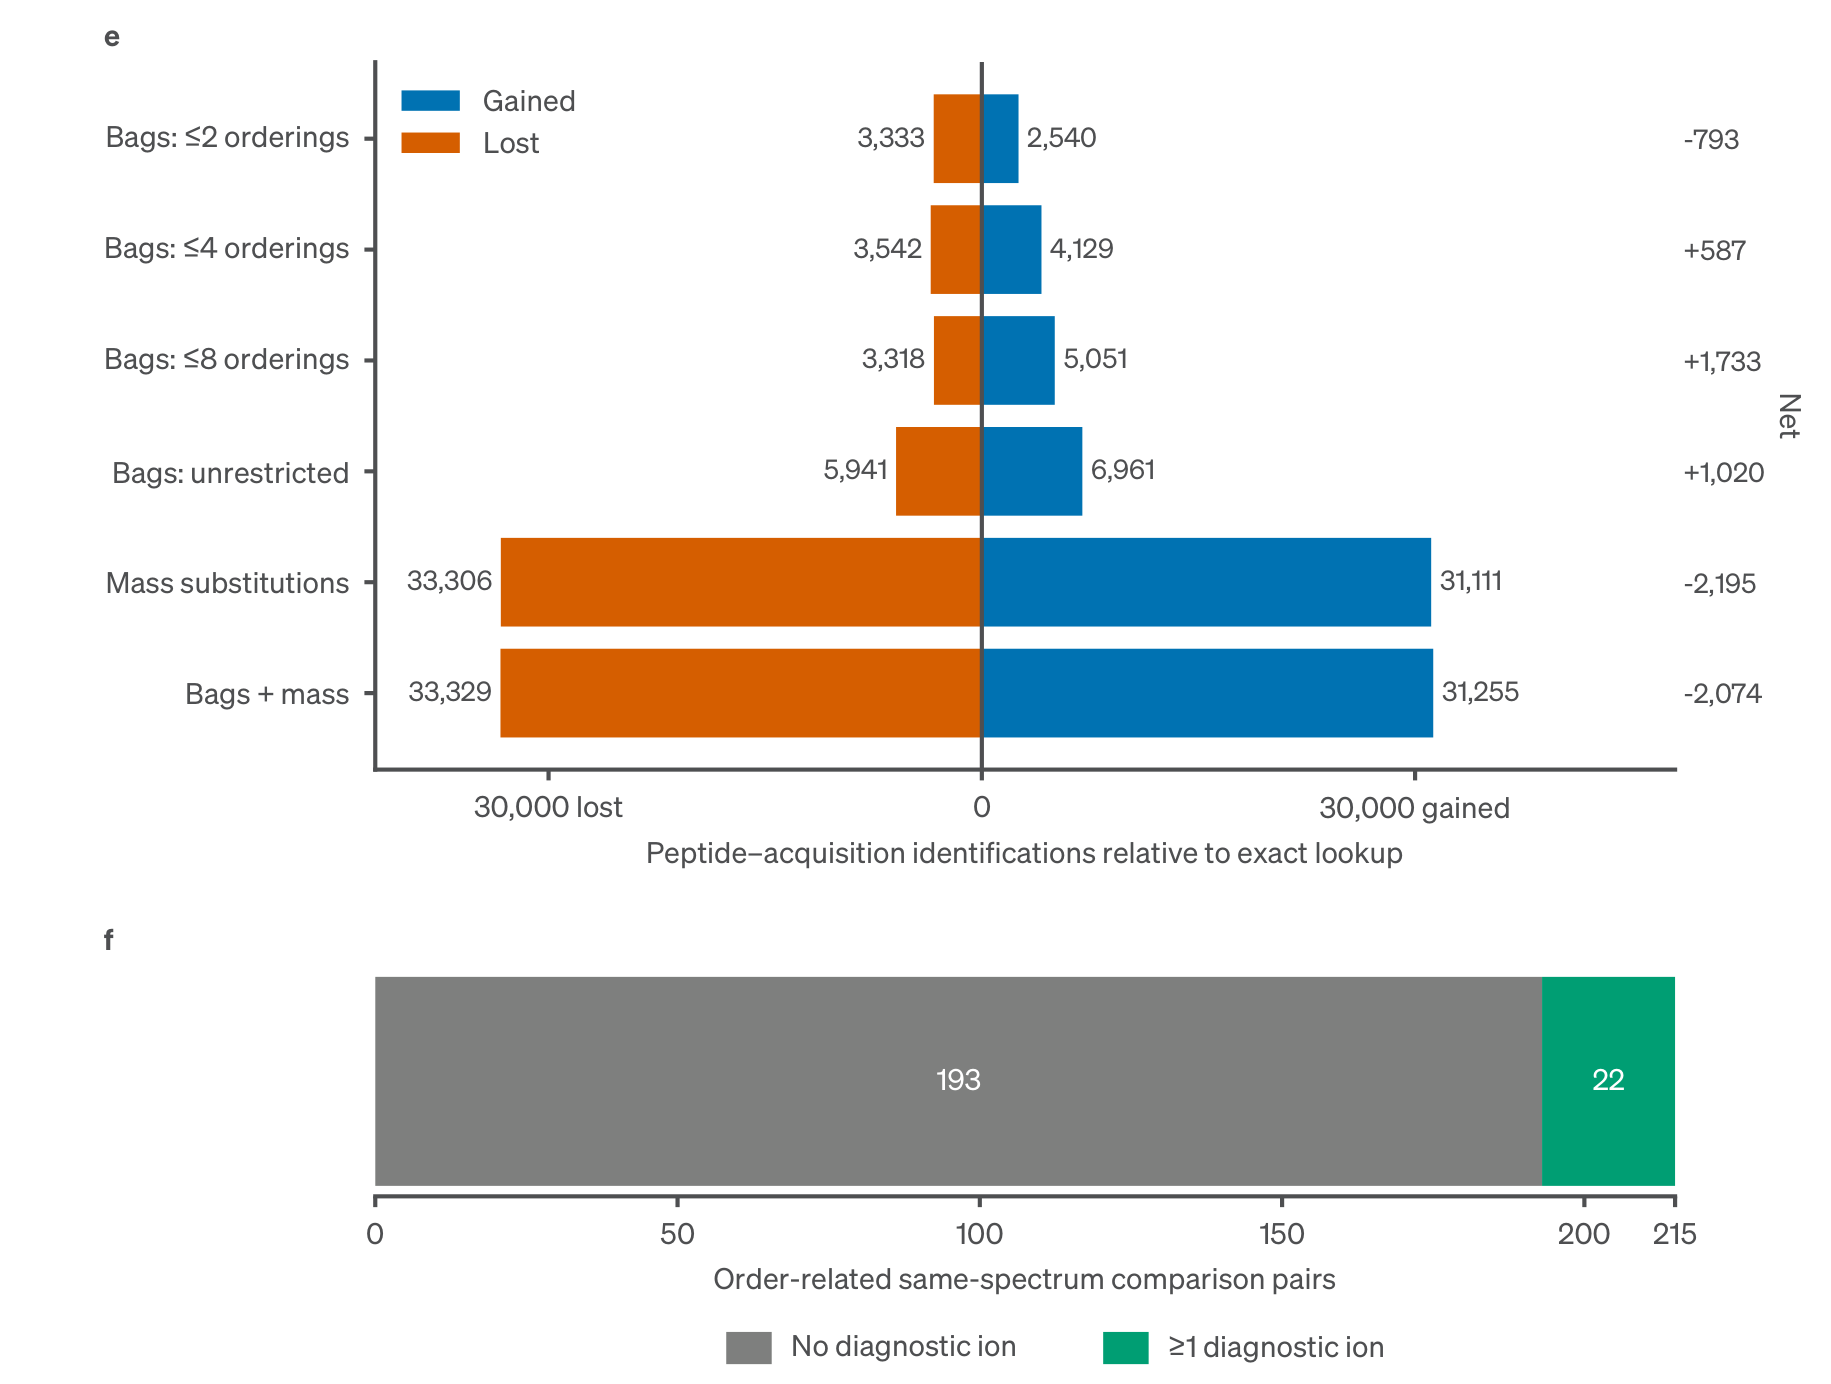

In [4]:
v30 = panels.build_v30(SD, OUT)
print("v30 values identical to producer: a-d", v30["values_identical_abcd"], "| e,f", v30["values_identical_ef"])
print("label strings lost (titles and composed labels only):", v30["label_strings_lost_abcd"], v30["label_strings_lost_ef"])
print("png px:", v30["png_px"])
display(Image(filename=str(OUT / "SFig02_v30.png"), width=700))
display(Image(filename=str(OUT / "SFig02_continued_v30.png"), width=700))


## Pixel checks and numbers

Each regenerated canvas is compared with the original producer's output: the vector PDFs at 300 dpi, and the two v28f images at their own resolution. The two v30 house-style images (Söhne text) are compared with the v30 PNGs at 300 dpi. Both producers used DejaVu Sans, which ships with matplotlib; the check is still gated on `FASTALAKE_FONT_DIR` as for every unit. Then every number in `NUMBERS.tsv` is recomputed and printed in file order.

In [5]:
import os, csv, re
if os.environ.get("FASTALAKE_FONT_DIR") or os.environ.get("FL_STYLE_DIR"):
    from tools.check_pixels import compare
    for name in ["panel_abcd.pdf", "SFig02_v28f.png", "panel_ef.pdf", "SFig02_continued_v28f.png",
                 "SFig02_v30.png", "SFig02_continued_v30.png"]:
        r = compare(OUT / name, UNIT / "expected" / name, UNIT / "checks" / name.split(".")[0], dpi=300)
        print(name, r["verdict"], r.get("differing_pixels"))
else:
    print("pixel checks SKIPPED: fonts absent")

cache = {}
with open(UNIT / "NUMBERS.tsv", encoding="utf-8") as fh:
    for row in csv.DictReader(fh, delimiter="\t"):
        if row["status"] == "OPEN":
            print(row["v28d_line"], row["printed_value"], "OPEN")
            continue
        fn, key = re.match(r".*:(\w+)\[(\w+)\]$", row["code"]).groups()
        if fn not in cache:
            cache[fn] = getattr(panels, fn)(SD)
        v = cache[fn][key]
        v = repr(v) if isinstance(v, float) else str(v)
        assert v == row["recomputed_value"], (row, v)
        print(row["v28d_line"], row["printed_value"], v, row["status"])

panel_abcd.pdf IDENTICAL 0


SFig02_v28f.png IDENTICAL 0


panel_ef.pdf IDENTICAL 0


SFig02_continued_v28f.png IDENTICAL 0


SFig02_v30.png IDENTICAL 0


SFig02_continued_v30.png IDENTICAL 0


59 8.1 8.076094759511845 MATCH
59 8.9% 8.883704235463028 MATCH
59 0.7 0.7009345794392523 MATCH
59 1.1% 1.0903426791277258 MATCH
59 86,000 85835 v28f_change:85,835
67 48 48 MATCH
67 6,961 6961 MATCH
67 5,941 5941 MATCH
67 +1,020 1020 MATCH
67 1,733 1733 MATCH
67 2,195 2195 MATCH
67 six six MATCH
67 193 193 MATCH
67 215 215 MATCH
409 five five MATCH
409 58 58 MATCH
409 1,102 1102 MATCH
413 48 48 MATCH
413 six six MATCH
413 193 193 MATCH
413 215 215 MATCH
413 22 22 MATCH
561 48 48 MATCH
561 15 15 MATCH
561 32 32 MATCH
561 one one MATCH
561 6,961 6961 MATCH
561 5,941 5941 MATCH
561 +1,020 1020 MATCH
561 38 38 MATCH
561 908,037 908037 MATCH
561 976,861 976861 MATCH
561 93.0% 92.95457593250217 MATCH
561 +5,051 5051 MATCH
561 3,318 3318 MATCH
561 +1,733 1733 MATCH
561 37 37 MATCH
561 −793 -793 MATCH
561 31,111 31111 MATCH
561 33,306 33306 MATCH
561 −2,195 -2195 MATCH
561 13 13 MATCH
561 32 32 MATCH
561 −5,242 -5242 MATCH
561 3 3 MATCH
561 13,512 OPEN
561 60 OPEN
579 48 48 MATCH
579 seven seve